In [100]:
import csv
with open("../data/raw/bank_data.csv", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)

    header = next(reader, None)

    if header is None:
        print("CSV file is empty!")
    else:
        print("Columns:", header)

        for i, row in enumerate(reader):
            if i < 254:
                print(row)

Columns: ['Customer_ID', 'City', 'Account_Type', 'Employment_Type', 'Preferred_Channel', 'Age', 'Monthly_Income_INR', 'Avg_Balance_INR', 'Monthly_Transactions', 'Complaints_Last_Year', 'Last_Transaction_Date', 'Satisfaction_Score']
['C1149', 'Mumbai', 'Savings', 'Salaried', 'Mobile_App', '31', '14500', '54600', '12', '1', '2025-11-13', '48.2']
['C1123', 'Delhi', 'Savings', 'Student', 'Net_Banking', '40', '56000', '155500', '16', '1', '2024-12-17', '60.9']
['C1215', 'Delhi', 'Savings', 'Self_Employed', 'Mobile_App', '55', '66000', '177400', '14', '1', '2025-05-21', '67.3']
['C1001', 'Mumbai', 'Salary', 'Retired', 'Mobile_App', '26', '78500', '414700', '33', '1', '2025-11-27', '94.2']
['C1009', 'Jaipur', 'Salary', 'Self_Employed', 'Net_Banking', '44', '62500', '717200', '12', '1', '2026-06-19', '78.6']
['C1102', 'Bengaluru', 'Salary', 'Salaried', 'Net_Banking', '36', '12000', '12200', '36', '0', '2026-07-18', '66.0']
['C1033', ' delhi', 'Savings', 'Salaried', 'Net_Banking', '53', '48500'

In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

# Plot style
sns.set_theme(style="whitegrid")

In [102]:
df = pd.read_csv("../data/raw/bank_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [103]:
df.head()

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score
0,C1149,Mumbai,Savings,Salaried,Mobile_App,31,14500.0,54600,12,1.0,2025-11-13,48.2
1,C1123,Delhi,Savings,Student,Net_Banking,40,56000.0,155500,16,1.0,2024-12-17,60.9
2,C1215,Delhi,Savings,Self_Employed,Mobile_App,55,66000.0,177400,14,1.0,2025-05-21,67.3
3,C1001,Mumbai,Salary,Retired,Mobile_App,26,78500.0,414700,33,1.0,2025-11-27,94.2
4,C1009,Jaipur,Salary,Self_Employed,Net_Banking,44,62500.0,717200,12,1.0,2026-06-19,78.6


In [104]:
df.tail()

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score
250,C1196,Jaipur,Salary,Salaried,Branch,34,37500.0,52700,13,1.0,2025-12-08,35.9
251,C1081,Pune,Savings,Student,Net_Banking,38,36000.0,103600,19,0.0,2025-11-04,56.4
252,C1105,Jaipur,Current,Student,ATM,20,41000.0,92400,9,1.0,2026-06-20,40.5
253,C1025,Mumbai,Current,Self_Employed,Net_Banking,45,68500.0,56100,17,0.0,2026-03-10,65.5
254,C1095,Jaipur,Savings,Salaried,Mobile_App,43,23000.0,11800,30,1.0,2025-12-17,52.5


In [105]:
print("Dataset shape:", df.shape)

print("Number of rows:", df.shape[0])

print("Number of columns:", df.shape[1])

Dataset shape: (255, 12)
Number of rows: 255
Number of columns: 12


In [106]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            255 non-null    str    
 1   City                   255 non-null    str    
 2   Account_Type           255 non-null    str    
 3   Employment_Type        255 non-null    str    
 4   Preferred_Channel      249 non-null    str    
 5   Age                    255 non-null    int64  
 6   Monthly_Income_INR     250 non-null    float64
 7   Avg_Balance_INR        255 non-null    int64  
 8   Monthly_Transactions   255 non-null    int64  
 9   Complaints_Last_Year   251 non-null    float64
 10  Last_Transaction_Date  250 non-null    str    
 11  Satisfaction_Score     255 non-null    float64
dtypes: float64(3), int64(3), str(6)
memory usage: 24.0 KB


In [107]:
df.describe()

,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Satisfaction_Score
count,255.000000,250.000000,2.550000e+02,255.000000,251.000000,255.000000
mean,38.556863,48036.000000,1.558451e+05,22.419608,1.011952,62.062353
std,15.981649,23584.052538,1.676596e+05,9.237910,0.997926,12.070495
min,-27.000000,12000.000000,9.900000e+03,2.000000,0.000000,29.400000
25%,30.000000,30750.000000,5.755000e+04,16.000000,0.000000,54.050000
50%,38.000000,42250.000000,1.014000e+05,22.000000,1.000000,61.900000
75%,45.000000,62500.000000,1.859000e+05,30.000000,2.000000,70.750000
max,212.000000,135000.000000,1.252900e+06,45.000000,5.000000,100.000000


In [108]:
df.describe(include = "all")

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score
count,255,255,255,255,249,255.000000,250.000000,2.550000e+02,255.000000,251.000000,250,255.000000
unique,250,11,3,4,4,NaN,NaN,NaN,NaN,NaN,214,NaN
top,C1145,Delhi,Savings,Salaried,Mobile_App,NaN,NaN,NaN,NaN,NaN,2025-11-13,NaN
freq,2,80,151,141,109,NaN,NaN,NaN,NaN,NaN,3,NaN
mean,NaN,NaN,NaN,NaN,NaN,38.556863,48036.000000,1.558451e+05,22.419608,1.011952,NaN,62.062353
std,NaN,NaN,NaN,NaN,NaN,15.981649,23584.052538,1.676596e+05,9.237910,0.997926,NaN,12.070495
min,NaN,NaN,NaN,NaN,NaN,-27.000000,12000.000000,9.900000e+03,2.000000,0.000000,NaN,29.400000
25%,NaN,NaN,NaN,NaN,NaN,30.000000,30750.000000,5.755000e+04,16.000000,0.000000,NaN,54.050000
50%,NaN,NaN,NaN,NaN,NaN,38.000000,42250.000000,1.014000e+05,22.000000,1.000000,NaN,61.900000
75%,NaN,NaN,NaN,NaN,NaN,45.000000,62500.000000,1.859000e+05,30.000000,2.000000,NaN,70.750000


In [109]:
df.isnull().sum()

Customer_ID              0
City                     0
Account_Type             0
Employment_Type          0
Preferred_Channel        6
Age                      0
Monthly_Income_INR       5
Avg_Balance_INR          0
Monthly_Transactions     0
Complaints_Last_Year     4
Last_Transaction_Date    5
Satisfaction_Score       0
dtype: int64

In [110]:
df.isnull().sum().sum()

np.int64(20)

In [111]:
(df.isnull().mean()*100).round(2)

Customer_ID              0.00
City                     0.00
Account_Type             0.00
Employment_Type          0.00
Preferred_Channel        2.35
Age                      0.00
Monthly_Income_INR       1.96
Avg_Balance_INR          0.00
Monthly_Transactions     0.00
Complaints_Last_Year     1.57
Last_Transaction_Date    1.96
Satisfaction_Score       0.00
dtype: float64

In [112]:
df.duplicated().sum()

np.int64(5)

In [113]:
df[df.duplicated()]

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score
105,C1242,Delhi,Savings,Salaried,Net_Banking,25,27500.0,57200,27,2.0,2025-08-08,59.7
131,C1115,Bengaluru,Savings,Retired,Net_Banking,25,68000.0,290900,17,0.0,2025-04-01,69.0
147,C1154,Mumbai,Savings,Self_Employed,Net_Banking,29,35500.0,66000,25,2.0,2025-08-31,59.2
167,C1166,Delhi,Savings,Salaried,Mobile_App,47,78000.0,475800,17,1.0,2026-02-05,67.2
213,C1145,Delhi,Savings,Salaried,Mobile_App,45,93500.0,416500,16,2.0,2025-11-15,67.1


In [114]:
print("City:")
print(df["City"].unique())

print("\nAccount Type:")
print(df["Account_Type"].unique())

print("\nEmployment Type:")
print(df["Employment_Type"].unique())

print("\nPreferred Channel:")
print(df["Preferred_Channel"].unique())

City:
<StringArray>
['Mumbai', 'Delhi', 'Jaipur', 'Bengaluru', ' delhi', 'Pune', 'pune', 'Delhi  ', '  Mumbai', 'Bengaluru  ', 'Mumbai  ']
Length: 11, dtype: str

Account Type:
<StringArray>
['Savings', 'Salary', 'Current']
Length: 3, dtype: str

Employment Type:
<StringArray>
['Salaried', 'Student', 'Self_Employed', 'Retired']
Length: 4, dtype: str

Preferred Channel:
<StringArray>
['Mobile_App', 'Net_Banking', 'ATM', 'Branch', nan]
Length: 5, dtype: str


In [115]:
df_row =df.copy()

In [116]:
# Creating a backup of the original dataset

df_raw = df.copy()

print("Backup created successfully!")
print("Original dataset shape:", df_raw.shape)


Backup created successfully!
Original dataset shape: (255, 12)


In [117]:
# Checking duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 5


In [118]:
# Display duplicate records

df[df.duplicated()]


,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score
105,C1242,Delhi,Savings,Salaried,Net_Banking,25,27500.0,57200,27,2.0,2025-08-08,59.7
131,C1115,Bengaluru,Savings,Retired,Net_Banking,25,68000.0,290900,17,0.0,2025-04-01,69.0
147,C1154,Mumbai,Savings,Self_Employed,Net_Banking,29,35500.0,66000,25,2.0,2025-08-31,59.2
167,C1166,Delhi,Savings,Salaried,Mobile_App,47,78000.0,475800,17,1.0,2026-02-05,67.2
213,C1145,Delhi,Savings,Salaried,Mobile_App,45,93500.0,416500,16,2.0,2025-11-15,67.1


In [119]:
# Removing duplicate records

df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("Shape after removing duplicates:", df.shape)


Duplicates removed successfully!
Shape after removing duplicates: (250, 12)


In [120]:
# Verifying duplicate removal

print("Remaining duplicate rows:", df.duplicated().sum())


Remaining duplicate rows: 0


In [121]:
# Checking categorical columns

categorical_columns = [
    "City",
    "Account_Type",
    "Employment_Type",
    "Preferred_Channel"
]

for column in categorical_columns:
    print("\nColumn:", column)
    print(df[column].value_counts(dropna=False))
    


Column: City
City
Delhi          77
Mumbai         65
Bengaluru      55
Pune           24
Jaipur         22
 delhi          2
pune            1
Delhi           1
  Mumbai        1
Bengaluru       1
Mumbai          1
Name: count, dtype: int64

Column: Account_Type
Account_Type
Savings    146
Salary      70
Current     34
Name: count, dtype: int64

Column: Employment_Type
Employment_Type
Salaried         138
Self_Employed     65
Student           27
Retired           20
Name: count, dtype: int64

Column: Preferred_Channel
Preferred_Channel
Mobile_App     107
Net_Banking     61
Branch          49
ATM             27
NaN              6
Name: count, dtype: int64


In [122]:
# Removing extra spaces and standardizing text case

for column in categorical_columns:
    df[column] = df[column].str.strip()
    

In [123]:
# Standardizing the case of categorical values

for column in categorical_columns:
    df[column] = df[column].str.lower()
    

In [124]:
# Checking categorical values after standardization

for column in categorical_columns:
    print("\nColumn:", column)
    print(df[column].value_counts(dropna=False))


Column: City
City
delhi        80
mumbai       67
bengaluru    56
pune         25
jaipur       22
Name: count, dtype: int64

Column: Account_Type
Account_Type
savings    146
salary      70
current     34
Name: count, dtype: int64

Column: Employment_Type
Employment_Type
salaried         138
self_employed     65
student           27
retired           20
Name: count, dtype: int64

Column: Preferred_Channel
Preferred_Channel
mobile_app     107
net_banking     61
branch          49
atm             27
NaN              6
Name: count, dtype: int64


In [125]:
# Selecting numerical columns

numeric_columns = [
    "Age",
    "Monthly_Income_INR",
    "Avg_Balance_INR",
    "Monthly_Transactions",
    "Complaints_Last_Year",
    "Satisfaction_Score"
]

print(numeric_columns)

['Age', 'Monthly_Income_INR', 'Avg_Balance_INR', 'Monthly_Transactions', 'Complaints_Last_Year', 'Satisfaction_Score']


In [126]:
# Checking minimum and maximum values of numerical columns

df[numeric_columns].agg(["min", "max"]).T

,min,max
Age,-27.0,212.0
Monthly_Income_INR,12000.0,135000.0
Avg_Balance_INR,9900.0,1252900.0
Monthly_Transactions,2.0,45.0
Complaints_Last_Year,0.0,5.0
Satisfaction_Score,29.4,100.0


In [127]:
# Checking invalid age values

invalid_age = df[(df["Age"] < 18) | (df["Age"] > 72)]

invalid_age

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score
74,C1128,delhi,savings,self_employed,branch,-27,80000.0,164100,18,3.0,2026-01-17,56.2
97,C1108,bengaluru,current,self_employed,mobile_app,212,59000.0,263100,26,0.0,2025-10-11,74.9


In [128]:
print("Invalid age values:", len(invalid_age))

Invalid age values: 2


In [129]:
# Checking invalid values in each numerical column

invalid_ranges = {
    "Age": (18, 72),
    "Monthly_Income_INR": (12000, 300000),
    "Avg_Balance_INR": (2000, 2500000),
    "Monthly_Transactions": (2, 60),
    "Complaints_Last_Year": (0, 6),
    "Satisfaction_Score": (20, 100)
}

for column, (minimum, maximum) in invalid_ranges.items():

    invalid = df[
        (df[column] < minimum) |
        (df[column] > maximum)
    ]

    print(
        column,
        "| Invalid count:", len(invalid),
        "| Minimum allowed:", minimum,
        "| Maximum allowed:", maximum
    )

Age | Invalid count: 2 | Minimum allowed: 18 | Maximum allowed: 72
Monthly_Income_INR | Invalid count: 0 | Minimum allowed: 12000 | Maximum allowed: 300000
Avg_Balance_INR | Invalid count: 0 | Minimum allowed: 2000 | Maximum allowed: 2500000
Monthly_Transactions | Invalid count: 0 | Minimum allowed: 2 | Maximum allowed: 60
Complaints_Last_Year | Invalid count: 0 | Minimum allowed: 0 | Maximum allowed: 6
Satisfaction_Score | Invalid count: 0 | Minimum allowed: 20 | Maximum allowed: 100


In [130]:
# Example pattern: marking invalid Age values as missing

df.loc[
    (df["Age"] < 18) | (df["Age"] > 72),
    "Age"
] = np.nan

In [131]:
# Checking missing values in each column

missing_count = df.isnull().sum()

print(missing_count)

Customer_ID              0
City                     0
Account_Type             0
Employment_Type          0
Preferred_Channel        6
Age                      2
Monthly_Income_INR       5
Avg_Balance_INR          0
Monthly_Transactions     0
Complaints_Last_Year     4
Last_Transaction_Date    5
Satisfaction_Score       0
dtype: int64


In [132]:
# Percentage of missing values in each column

missing_percentage = (
    df.isnull().mean() * 100
).round(2)

print(missing_percentage)

Customer_ID              0.0
City                     0.0
Account_Type             0.0
Employment_Type          0.0
Preferred_Channel        2.4
Age                      0.8
Monthly_Income_INR       2.0
Avg_Balance_INR          0.0
Monthly_Transactions     0.0
Complaints_Last_Year     1.6
Last_Transaction_Date    2.0
Satisfaction_Score       0.0
dtype: float64


In [133]:
# Display rows that contain at least one missing value

df[df.isnull().any(axis=1)]

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score
8,C1043,delhi,current,salaried,mobile_app,48.0,NaN,78500,33,2.0,2025-01-09,60.2
22,C1100,pune,savings,salaried,branch,50.0,36500.0,66700,20,2.0,NaN,48.8
35,C1085,bengaluru,savings,salaried,net_banking,44.0,NaN,62200,2,0.0,2026-03-16,56.2
43,C1138,mumbai,current,salaried,NaN,57.0,48000.0,169300,33,0.0,2026-07-17,76.0
48,C1118,delhi,salary,self_employed,NaN,39.0,15000.0,28600,19,3.0,2025-07-31,36.5
57,C1212,delhi,savings,self_employed,mobile_app,20.0,79500.0,474400,26,NaN,2025-05-11,84.8
74,C1128,delhi,savings,self_employed,branch,NaN,80000.0,164100,18,3.0,2026-01-17,56.2
80,C1232,jaipur,salary,self_employed,net_banking,58.0,31500.0,150000,30,NaN,2025-01-19,73.9
93,C1178,pune,salary,self_employed,NaN,24.0,39500.0,58100,19,1.0,2025-03-10,69.2
97,C1108,bengaluru,current,self_employed,mobile_app,NaN,59000.0,263100,26,0.0,2025-10-11,74.9


In [134]:
# Missing values in numerical columns

df[numeric_columns].isnull().sum()

Age                     2
Monthly_Income_INR      5
Avg_Balance_INR         0
Monthly_Transactions    0
Complaints_Last_Year    4
Satisfaction_Score      0
dtype: int64

In [135]:
# Missing values in categorical columns

df[categorical_columns].isnull().sum()

City                 0
Account_Type         0
Employment_Type      0
Preferred_Channel    6
dtype: int64

In [136]:
# Example: filling missing Age values with the median

age_median = df["Age"].median()

df["Age"] = df["Age"].fillna(age_median)

print("Missing Age values filled.")

Missing Age values filled.


In [137]:
# Example: filling missing City values using the mode

city_mode = df["City"].mode()[0]

df["City"] = df["City"].fillna(city_mode)

print("Missing City values filled.")

Missing City values filled.


In [138]:
print(df["Last_Transaction_Date"].dtype)

str


In [139]:
# Converting the transaction date into datetime format

df["Last_Transaction_Date"] = pd.to_datetime(
    df["Last_Transaction_Date"],
    errors="coerce"
)

print("Date conversion completed!")
print(df["Last_Transaction_Date"].dtype)

Date conversion completed!
datetime64[us]


In [140]:
# Final dataset shape

print("Final dataset shape:", df.shape)

print("Total rows:", df.shape[0])

print("Total columns:", df.shape[1])

Final dataset shape: (250, 12)
Total rows: 250
Total columns: 12


In [141]:
# Final missing value check

print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values per column:
Customer_ID              0
City                     0
Account_Type             0
Employment_Type          0
Preferred_Channel        6
Age                      0
Monthly_Income_INR       5
Avg_Balance_INR          0
Monthly_Transactions     0
Complaints_Last_Year     4
Last_Transaction_Date    5
Satisfaction_Score       0
dtype: int64

Total missing values:
20


In [142]:
# Final duplicate check

print("Remaining duplicate rows:", df.duplicated().sum())

Remaining duplicate rows: 0


In [143]:
# Final data types

df.info()

<class 'pandas.DataFrame'>
Index: 250 entries, 0 to 254
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Customer_ID            250 non-null    str           
 1   City                   250 non-null    str           
 2   Account_Type           250 non-null    str           
 3   Employment_Type        250 non-null    str           
 4   Preferred_Channel      244 non-null    str           
 5   Age                    250 non-null    float64       
 6   Monthly_Income_INR     245 non-null    float64       
 7   Avg_Balance_INR        250 non-null    int64         
 8   Monthly_Transactions   250 non-null    int64         
 9   Complaints_Last_Year   246 non-null    float64       
 10  Last_Transaction_Date  245 non-null    datetime64[us]
 11  Satisfaction_Score     250 non-null    float64       
dtypes: datetime64[us](1), float64(4), int64(2), str(5)
memory usage: 25.4 KB


In [144]:
# Final numerical summary

df[numeric_columns].describe()

,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Satisfaction_Score
count,250.000000,245.000000,2.500000e+02,250.00000,246.000000,250.00000
mean,38.208000,47781.632653,1.537364e+05,22.46000,1.004065,62.01480
std,10.956868,23481.556012,1.668562e+05,9.30261,0.999992,12.17225
min,18.000000,12000.000000,9.900000e+03,2.00000,0.000000,29.40000
25%,31.000000,30500.000000,5.747500e+04,16.00000,0.000000,53.77500
50%,38.000000,42000.000000,1.009500e+05,22.00000,1.000000,61.80000
75%,45.000000,62500.000000,1.837250e+05,30.00000,1.000000,70.80000
max,70.000000,135000.000000,1.252900e+06,45.00000,5.000000,100.00000


In [145]:
# Final category check

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts(dropna=False))


 City
City
delhi        80
mumbai       67
bengaluru    56
pune         25
jaipur       22
Name: count, dtype: int64

 Account_Type
Account_Type
savings    146
salary      70
current     34
Name: count, dtype: int64

 Employment_Type
Employment_Type
salaried         138
self_employed     65
student           27
retired           20
Name: count, dtype: int64

 Preferred_Channel
Preferred_Channel
mobile_app     107
net_banking     61
branch          49
atm             27
NaN              6
Name: count, dtype: int64


In [146]:
# Creating a final data quality summary

cleaning_summary = pd.DataFrame({
    "Check": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Total Missing Values"
    ],

    "Result": [
        df.shape[0],
        df.shape[1],
        df.duplicated().sum(),
        df.isnull().sum().sum()
    ]
})

cleaning_summary

,Check,Result
0,Total Rows,250
1,Total Columns,12
2,Duplicate Rows,0
3,Total Missing Values,20


In [147]:
df["Balance_Income_Ratio"] = (
    df["Avg_Balance_INR"] / df["Monthly_Income_INR"]
)

df.head()

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score,Balance_Income_Ratio
0,C1149,mumbai,savings,salaried,mobile_app,31.0,14500.0,54600,12,1.0,2025-11-13,48.2,3.765517
1,C1123,delhi,savings,student,net_banking,40.0,56000.0,155500,16,1.0,2024-12-17,60.9,2.776786
2,C1215,delhi,savings,self_employed,mobile_app,55.0,66000.0,177400,14,1.0,2025-05-21,67.3,2.687879
3,C1001,mumbai,salary,retired,mobile_app,26.0,78500.0,414700,33,1.0,2025-11-27,94.2,5.282803
4,C1009,jaipur,salary,self_employed,net_banking,44.0,62500.0,717200,12,1.0,2026-06-19,78.6,11.475200


In [148]:
df["Balance_Income_Ratio"].describe()

count    245.000000
mean       3.108898
std        2.633026
min        0.307042
25%        1.613423
50%        2.453846
75%        3.771429
max       25.832990
Name: Balance_Income_Ratio, dtype: float64

In [149]:
df[[
    "Customer_ID",
    "Monthly_Income_INR",
    "Avg_Balance_INR",
    "Balance_Income_Ratio"
]].head(10)

,Customer_ID,Monthly_Income_INR,Avg_Balance_INR,Balance_Income_Ratio
0,C1149,14500.0,54600,3.765517
1,C1123,56000.0,155500,2.776786
2,C1215,66000.0,177400,2.687879
3,C1001,78500.0,414700,5.282803
4,C1009,62500.0,717200,11.475200
5,C1102,12000.0,12200,1.016667
6,C1033,48500.0,150300,3.098969
7,C1087,46500.0,29800,0.640860
8,C1043,NaN,78500,NaN
9,C1064,79000.0,127000,1.607595


In [150]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 50, 72],
    labels=["18-25", "26-35", "36-50", "51+"]
)

df.head()

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score,Balance_Income_Ratio,Age_Group
0,C1149,mumbai,savings,salaried,mobile_app,31.0,14500.0,54600,12,1.0,2025-11-13,48.2,3.765517,26-35
1,C1123,delhi,savings,student,net_banking,40.0,56000.0,155500,16,1.0,2024-12-17,60.9,2.776786,36-50
2,C1215,delhi,savings,self_employed,mobile_app,55.0,66000.0,177400,14,1.0,2025-05-21,67.3,2.687879,51+
3,C1001,mumbai,salary,retired,mobile_app,26.0,78500.0,414700,33,1.0,2025-11-27,94.2,5.282803,26-35
4,C1009,jaipur,salary,self_employed,net_banking,44.0,62500.0,717200,12,1.0,2026-06-19,78.6,11.475200,36-50


In [151]:
df["Age_Group"].value_counts().sort_index()

Age_Group
18-25     35
26-35     67
36-50    110
51+       38
Name: count, dtype: int64

In [152]:
df["Age_Group"].value_counts(
    normalize=True
).sort_index() * 100

Age_Group
18-25    14.0
26-35    26.8
36-50    44.0
51+      15.2
Name: proportion, dtype: float64

In [153]:
df["Satisfaction_Category"] = pd.cut(
    df["Satisfaction_Score"],
    bins=[19, 49, 74, 100],
    labels=["Low", "Medium", "High"]
)

df.head()

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score,Balance_Income_Ratio,Age_Group,Satisfaction_Category
0,C1149,mumbai,savings,salaried,mobile_app,31.0,14500.0,54600,12,1.0,2025-11-13,48.2,3.765517,26-35,Low
1,C1123,delhi,savings,student,net_banking,40.0,56000.0,155500,16,1.0,2024-12-17,60.9,2.776786,36-50,Medium
2,C1215,delhi,savings,self_employed,mobile_app,55.0,66000.0,177400,14,1.0,2025-05-21,67.3,2.687879,51+,Medium
3,C1001,mumbai,salary,retired,mobile_app,26.0,78500.0,414700,33,1.0,2025-11-27,94.2,5.282803,26-35,High
4,C1009,jaipur,salary,self_employed,net_banking,44.0,62500.0,717200,12,1.0,2026-06-19,78.6,11.475200,36-50,High


In [154]:
df["Satisfaction_Category"].value_counts()

Satisfaction_Category
Medium    172
High       40
Low        38
Name: count, dtype: int64

In [155]:
df["Satisfaction_Category"].value_counts(
    normalize=True
) * 100

Satisfaction_Category
Medium    68.8
High      16.0
Low       15.2
Name: proportion, dtype: float64

In [156]:
new_columns = [
    "Balance_Income_Ratio",
    "Age_Group",
    "Satisfaction_Category"
]

df[new_columns].head(10)

,Balance_Income_Ratio,Age_Group,Satisfaction_Category
0,3.765517,26-35,Low
1,2.776786,36-50,Medium
2,2.687879,51+,Medium
3,5.282803,26-35,High
4,11.475200,36-50,High
5,1.016667,36-50,Medium
6,3.098969,51+,Medium
7,0.640860,36-50,Low
8,NaN,36-50,Medium
9,1.607595,51+,High


In [157]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

Total rows: 250
Total columns: 15

Column names:
['Customer_ID', 'City', 'Account_Type', 'Employment_Type', 'Preferred_Channel', 'Age', 'Monthly_Income_INR', 'Avg_Balance_INR', 'Monthly_Transactions', 'Complaints_Last_Year', 'Last_Transaction_Date', 'Satisfaction_Score', 'Balance_Income_Ratio', 'Age_Group', 'Satisfaction_Category']


In [158]:
print("Missing values in new features:")
print(df[new_columns].isnull().sum())

Missing values in new features:
Balance_Income_Ratio     5
Age_Group                0
Satisfaction_Category    0
dtype: int64


<Axes: title={'center': 'Customer Distribution by Age Group'}, xlabel='Age Group', ylabel='Number of Customers'>

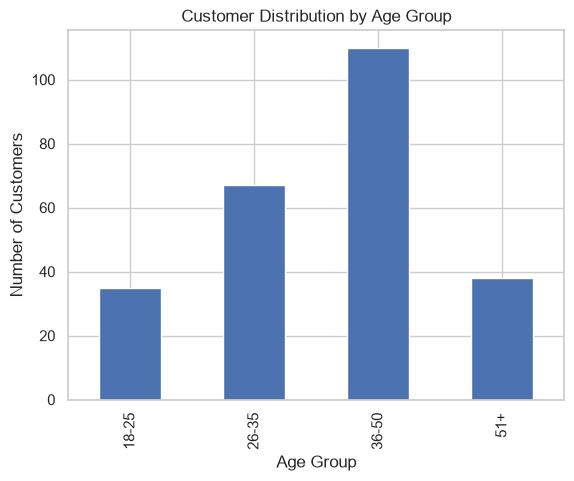

In [159]:
df["Age_Group"].value_counts().sort_index().plot(
    kind="bar",
    title="Customer Distribution by Age Group",
    xlabel="Age Group",
    ylabel="Number of Customers"
)


<Axes: title={'center': 'Customer Distribution by Satisfaction Category'}, xlabel='Satisfaction Category', ylabel='Number of Customers'>

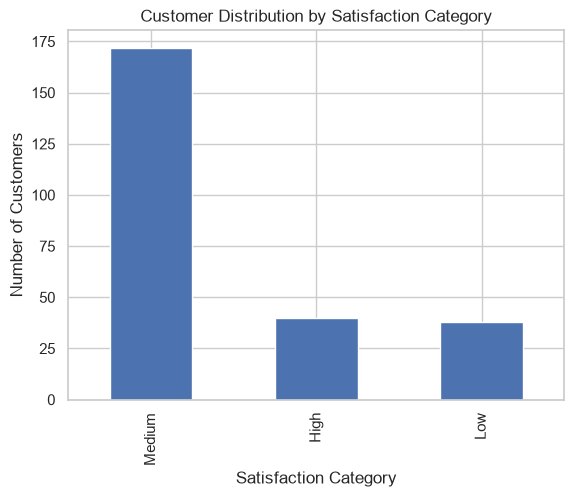

In [160]:
df["Satisfaction_Category"].value_counts().plot(
    kind="bar",
    title="Customer Distribution by Satisfaction Category",
    xlabel="Satisfaction Category",
    ylabel="Number of Customers"
)

In [161]:
df.describe()

,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score,Balance_Income_Ratio
count,250.000000,245.000000,2.500000e+02,250.00000,246.000000,245,250.00000,245.000000
mean,38.208000,47781.632653,1.537364e+05,22.46000,1.004065,2025-11-19 11:45:18.367347,62.01480,3.108898
min,18.000000,12000.000000,9.900000e+03,2.00000,0.000000,2024-11-19 00:00:00,29.40000,0.307042
25%,31.000000,30500.000000,5.747500e+04,16.00000,0.000000,2025-05-09 00:00:00,53.77500,1.613423
50%,38.000000,42000.000000,1.009500e+05,22.00000,1.000000,2025-12-08 00:00:00,61.80000,2.453846
75%,45.000000,62500.000000,1.837250e+05,30.00000,1.000000,2026-05-21 00:00:00,70.80000,3.771429
max,70.000000,135000.000000,1.252900e+06,45.00000,5.000000,2026-11-18 00:00:00,100.00000,25.832990
std,10.956868,23481.556012,1.668562e+05,9.30261,0.999992,NaN,12.17225,2.633026


In [162]:
categorical_columns = [
    "City",
    "Account_Type",
    "Employment_Type",
    "Preferred_Channel",
    "Age_Group",
    "Satisfaction_Category"
]

for column in categorical_columns:
    print("\n---", column, "---")
    print(df[column].value_counts())


--- City ---
City
delhi        80
mumbai       67
bengaluru    56
pune         25
jaipur       22
Name: count, dtype: int64

--- Account_Type ---
Account_Type
savings    146
salary      70
current     34
Name: count, dtype: int64

--- Employment_Type ---
Employment_Type
salaried         138
self_employed     65
student           27
retired           20
Name: count, dtype: int64

--- Preferred_Channel ---
Preferred_Channel
mobile_app     107
net_banking     61
branch          49
atm             27
Name: count, dtype: int64

--- Age_Group ---
Age_Group
36-50    110
26-35     67
51+       38
18-25     35
Name: count, dtype: int64

--- Satisfaction_Category ---
Satisfaction_Category
Medium    172
High       40
Low        38
Name: count, dtype: int64


In [163]:
print("Mean Satisfaction:", df["Satisfaction_Score"].mean())
print("Median Satisfaction:", df["Satisfaction_Score"].median())
print("Minimum Satisfaction:", df["Satisfaction_Score"].min())
print("Maximum Satisfaction:", df["Satisfaction_Score"].max())
print("Standard Deviation:", df["Satisfaction_Score"].std())

Mean Satisfaction: 62.0148
Median Satisfaction: 61.8
Minimum Satisfaction: 29.4
Maximum Satisfaction: 100.0
Standard Deviation: 12.172250230037609


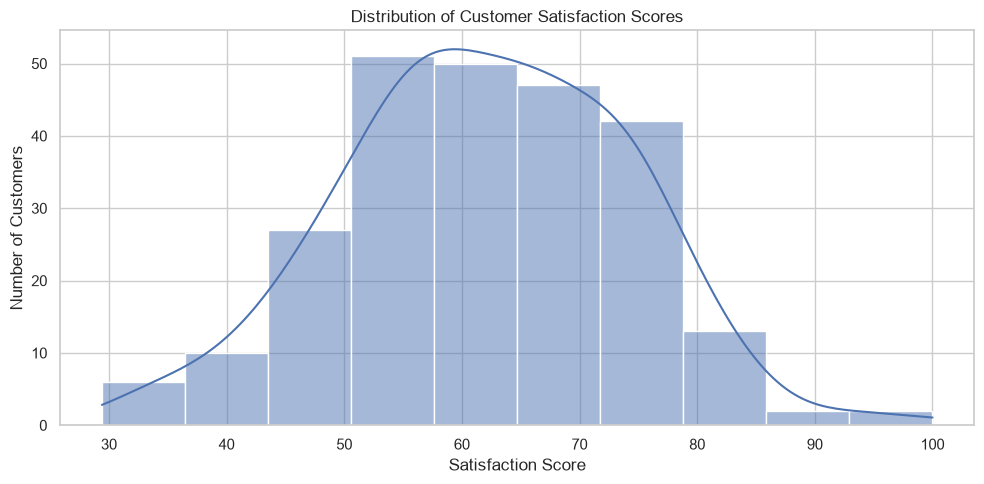

In [164]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Satisfaction_Score",
    bins=10,
    kde=True
)

plt.title("Distribution of Customer Satisfaction Scores")
plt.xlabel("Satisfaction Score")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("../images/01_overall_satisfaction.png", dpi=300)
plt.show()

In [165]:
satisfaction_counts = df["Satisfaction_Category"].value_counts()

print(satisfaction_counts)

Satisfaction_Category
Medium    172
High       40
Low        38
Name: count, dtype: int64


In [166]:
satisfaction_percentages = (
    df["Satisfaction_Category"]
    .value_counts(normalize=True)
    * 100
)

print(satisfaction_percentages.round(2))

Satisfaction_Category
Medium    68.8
High      16.0
Low       15.2
Name: proportion, dtype: float64


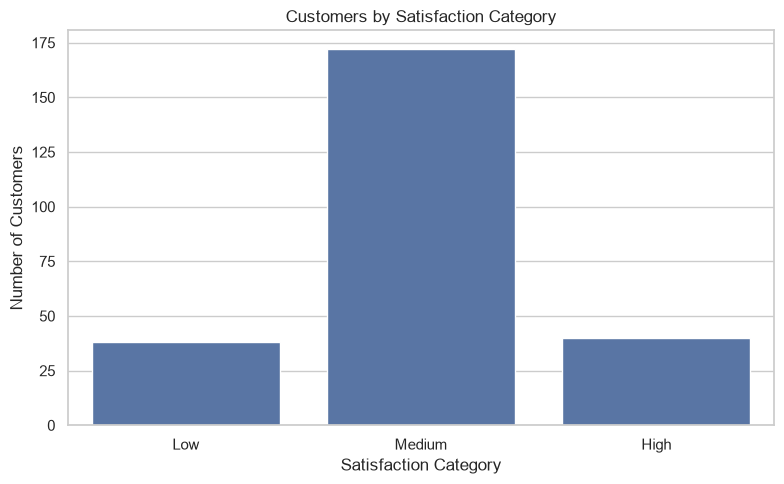

In [167]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Satisfaction_Category",
    order=["Low", "Medium", "High"]
)

plt.title("Customers by Satisfaction Category")
plt.xlabel("Satisfaction Category")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

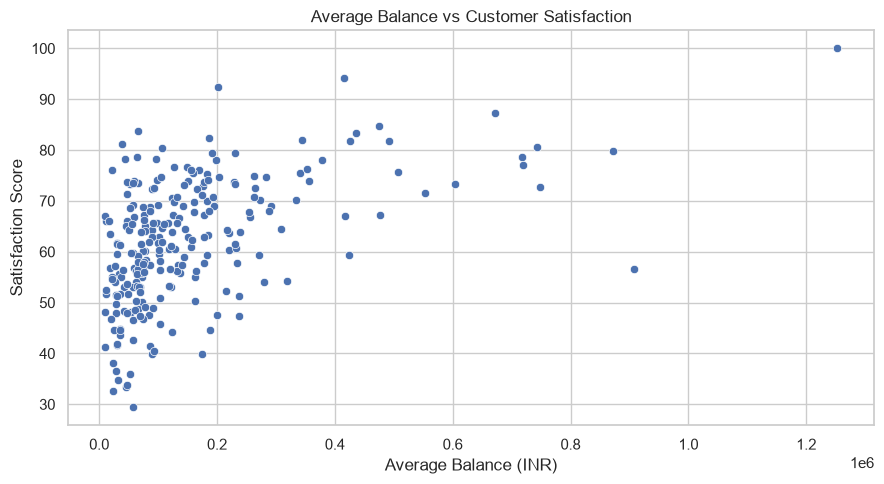

In [168]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Avg_Balance_INR",
    y="Satisfaction_Score"
)

plt.title("Average Balance vs Customer Satisfaction")
plt.xlabel("Average Balance (INR)")
plt.ylabel("Satisfaction Score")

plt.tight_layout()
plt.savefig("../images/02_balance_transactions.png", dpi=300)
plt.show()

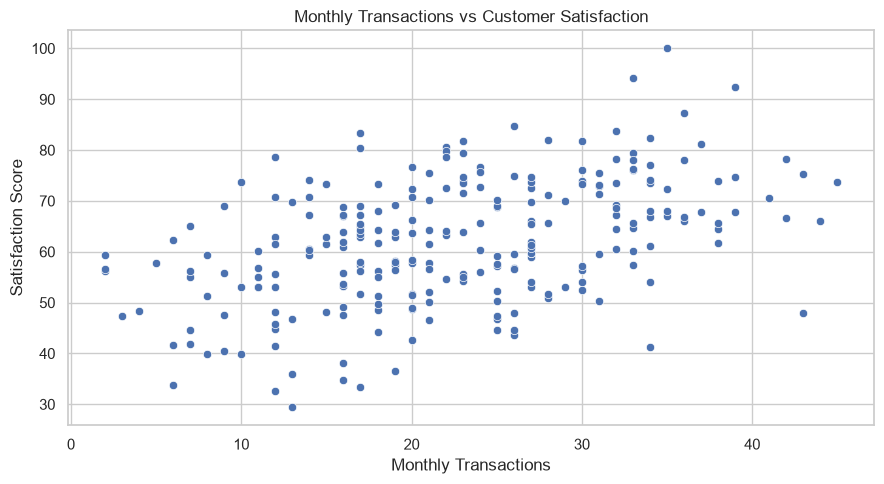

In [169]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Monthly_Transactions",
    y="Satisfaction_Score"
)

plt.title("Monthly Transactions vs Customer Satisfaction")
plt.xlabel("Monthly Transactions")
plt.ylabel("Satisfaction Score")

plt.tight_layout()
plt.show()

In [170]:
correlation = df[numeric_columns].corr()

correlation

,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Satisfaction_Score
Age,1.000000,0.000477,-0.052281,0.065843,-0.011784,0.024377
Monthly_Income_INR,0.000477,1.000000,0.541179,0.025651,-0.090024,0.356167
Avg_Balance_INR,-0.052281,0.541179,1.000000,0.027943,-0.067854,0.492602
Monthly_Transactions,0.065843,0.025651,0.027943,1.000000,0.093217,0.459362
Complaints_Last_Year,-0.011784,-0.090024,-0.067854,0.093217,1.000000,-0.183476
Satisfaction_Score,0.024377,0.356167,0.492602,0.459362,-0.183476,1.000000


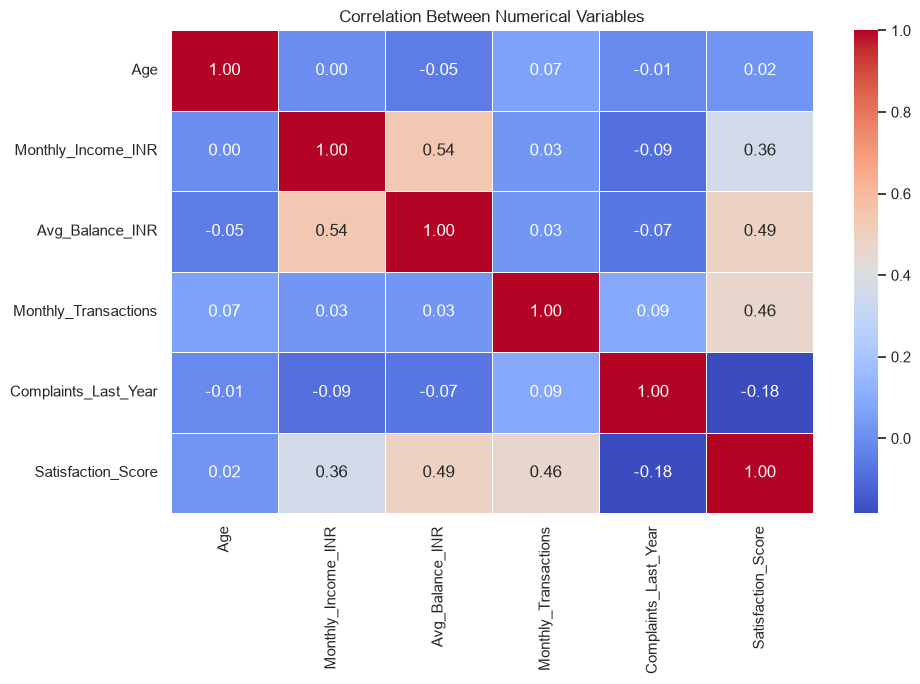

In [171]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Variables")

plt.tight_layout()
plt.savefig("../images/03_correlation.png", dpi=300)
plt.show()

In [172]:
city_satisfaction = (
    df.groupby("City")["Satisfaction_Score"]
    .mean()
    .sort_values(ascending=False)
)

print(city_satisfaction)

City
mumbai       64.794030
bengaluru    62.183929
pune         61.756000
jaipur       60.200000
delhi        60.148750
Name: Satisfaction_Score, dtype: float64


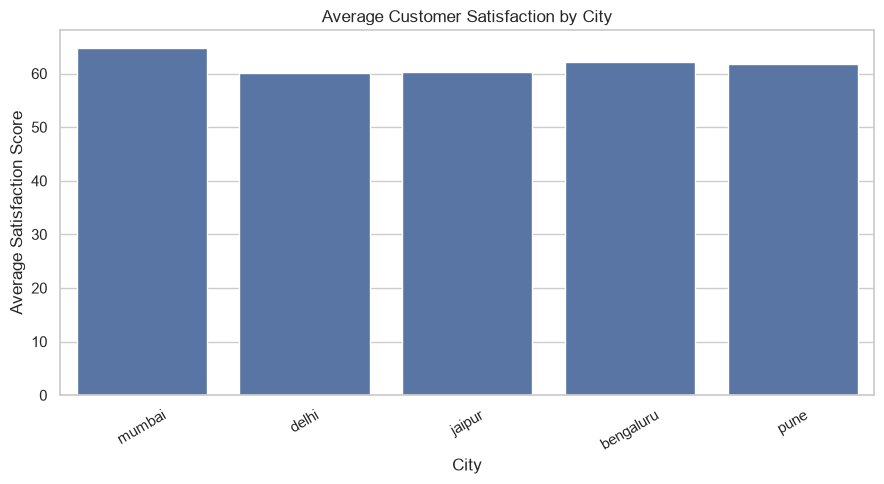

In [173]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="City",
    y="Satisfaction_Score",
    errorbar=None
)

plt.title("Average Customer Satisfaction by City")
plt.xlabel("City")
plt.ylabel("Average Satisfaction Score")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [174]:
account_satisfaction = (
    df.groupby("Account_Type")["Satisfaction_Score"]
    .mean()
    .sort_values(ascending=False)
)

print(account_satisfaction)

Account_Type
savings    63.068493
current    62.576471
salary     59.544286
Name: Satisfaction_Score, dtype: float64


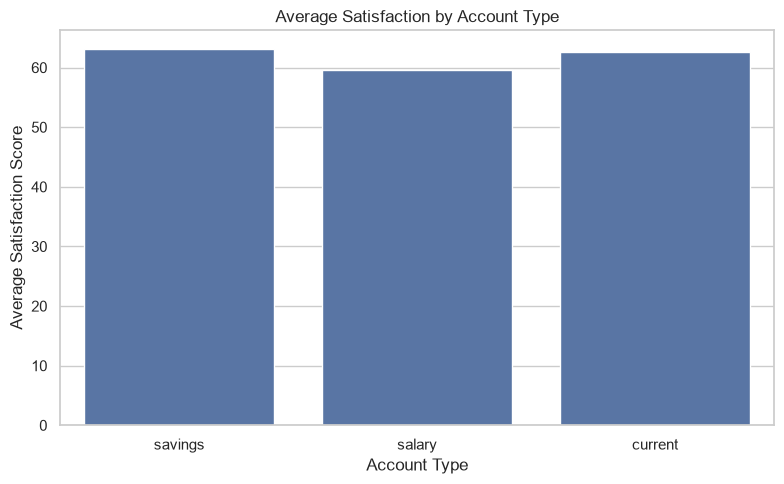

In [175]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Account_Type",
    y="Satisfaction_Score",
    errorbar=None
)

plt.title("Average Satisfaction by Account Type")
plt.xlabel("Account Type")
plt.ylabel("Average Satisfaction Score")

plt.tight_layout()
plt.show()

In [176]:
employment_satisfaction = (
    df.groupby("Employment_Type")["Satisfaction_Score"]
    .mean()
    .sort_values(ascending=False)
)

print(employment_satisfaction)

Employment_Type
retired          65.075000
self_employed    63.103077
student          61.433333
salaried         61.172464
Name: Satisfaction_Score, dtype: float64


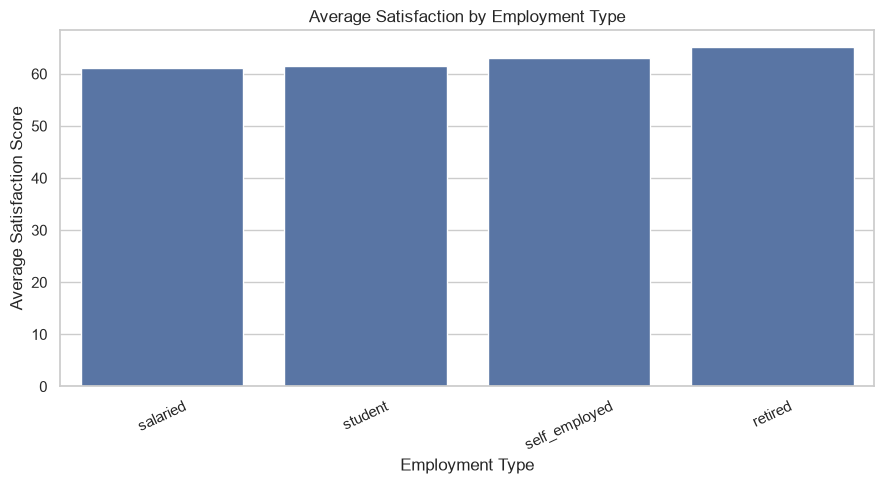

In [177]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Employment_Type",
    y="Satisfaction_Score",
    errorbar=None
)

plt.title("Average Satisfaction by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Average Satisfaction Score")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

In [178]:
channel_satisfaction = (
    df.groupby("Preferred_Channel")["Satisfaction_Score"]
    .mean()
    .sort_values(ascending=False)
)

print(channel_satisfaction)

Preferred_Channel
mobile_app     64.140187
net_banking    62.077049
atm            61.329630
branch         57.848980
Name: Satisfaction_Score, dtype: float64


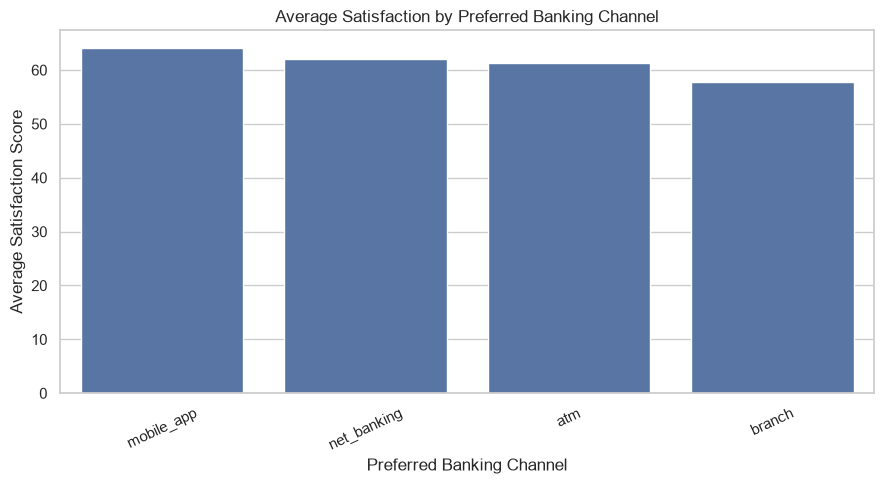

In [179]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Preferred_Channel",
    y="Satisfaction_Score",
    errorbar=None
)

plt.title("Average Satisfaction by Preferred Banking Channel")
plt.xlabel("Preferred Banking Channel")
plt.ylabel("Average Satisfaction Score")
plt.xticks(rotation=25)

plt.tight_layout()
plt.savefig("../images/04_group_comparison.png", dpi=300)
plt.show()

In [180]:
age_satisfaction = (
    df.groupby("Age_Group", observed=True)["Satisfaction_Score"]
    .mean()
)

print(age_satisfaction)

Age_Group
18-25    61.465714
26-35    61.285075
36-50    61.867273
51+      64.234211
Name: Satisfaction_Score, dtype: float64


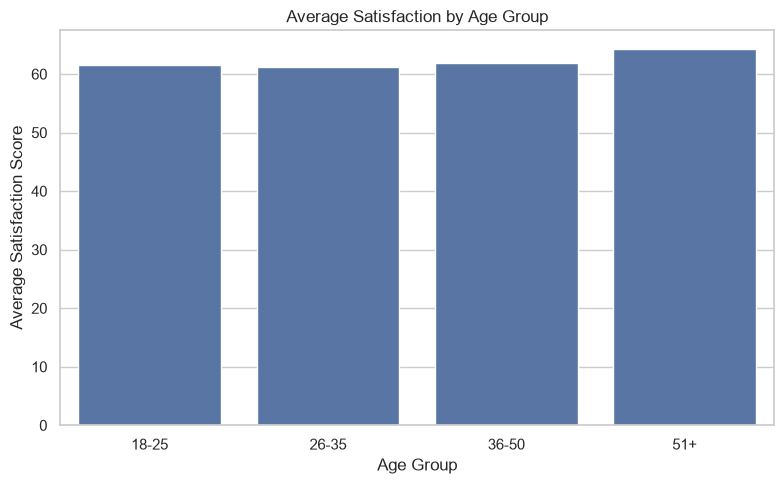

In [181]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Age_Group",
    y="Satisfaction_Score",
    errorbar=None
)

plt.title("Average Satisfaction by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Satisfaction Score")

plt.tight_layout()
plt.show()

In [182]:
at_risk_customers = df[
    df["Satisfaction_Score"] < 50
].copy()

at_risk_customers.head()

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score,Balance_Income_Ratio,Age_Group,Satisfaction_Category
0,C1149,mumbai,savings,salaried,mobile_app,31.0,14500.0,54600,12,1.0,2025-11-13,48.2,3.765517,26-35,Low
7,C1087,mumbai,salary,salaried,mobile_app,48.0,46500.0,29800,6,0.0,2026-07-12,41.6,0.640860,36-50,Low
14,C1243,bengaluru,salary,salaried,atm,61.0,60000.0,123400,18,1.0,2025-12-21,44.3,2.056667,51+,Low
16,C1218,jaipur,savings,salaried,net_banking,31.0,31500.0,35400,26,1.0,2026-05-29,43.7,1.123810,26-35,Low
22,C1100,pune,savings,salaried,branch,50.0,36500.0,66700,20,2.0,NaT,48.8,1.827397,36-50,Low


In [183]:
total_customers = len(df)

at_risk_count = len(at_risk_customers)

at_risk_percentage = (
    at_risk_count / total_customers
) * 100

print("Total Customers:", total_customers)
print("At-Risk Customers:", at_risk_count)
print("At-Risk Percentage:", round(at_risk_percentage, 2), "%")

Total Customers: 250
At-Risk Customers: 40
At-Risk Percentage: 16.0 %


In [184]:
at_risk_customers[
    [
        "Customer_ID",
        "City",
        "Age",
        "Age_Group",
        "Account_Type",
        "Employment_Type",
        "Preferred_Channel",
        "Monthly_Income_INR",
        "Avg_Balance_INR",
        "Monthly_Transactions",
        "Complaints_Last_Year",
        "Satisfaction_Score"
    ]
].head(20)

,Customer_ID,City,Age,Age_Group,Account_Type,Employment_Type,Preferred_Channel,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Satisfaction_Score
0,C1149,mumbai,31.0,26-35,savings,salaried,mobile_app,14500.0,54600,12,1.0,48.2
7,C1087,mumbai,48.0,36-50,salary,salaried,mobile_app,46500.0,29800,6,0.0,41.6
14,C1243,bengaluru,61.0,51+,salary,salaried,atm,60000.0,123400,18,1.0,44.3
16,C1218,jaipur,31.0,26-35,savings,salaried,net_banking,31500.0,35400,26,1.0,43.7
22,C1100,pune,50.0,36-50,savings,salaried,branch,36500.0,66700,20,2.0,48.8
24,C1214,mumbai,42.0,36-50,savings,self_employed,branch,22000.0,56600,20,0.0,42.6
39,C1129,delhi,44.0,36-50,current,salaried,net_banking,28500.0,23600,16,2.0,38.1
48,C1118,delhi,39.0,36-50,salary,self_employed,NaN,15000.0,28600,19,3.0,36.5
55,C1190,mumbai,49.0,36-50,savings,self_employed,mobile_app,37000.0,35000,12,0.0,44.8
58,C1211,bengaluru,40.0,36-50,savings,self_employed,net_banking,31500.0,102900,12,1.0,45.7


In [185]:
at_risk_city = at_risk_customers["City"].value_counts()

print(at_risk_city)

City
mumbai       11
bengaluru    11
delhi        10
jaipur        4
pune          4
Name: count, dtype: int64


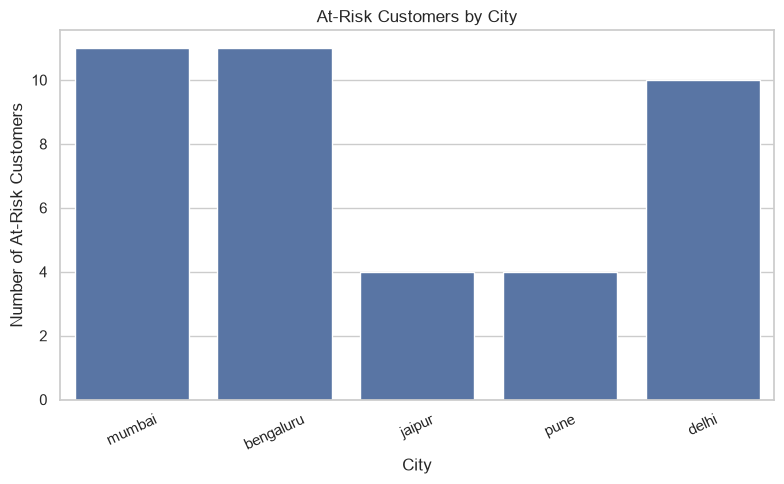

In [186]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=at_risk_customers,
    x="City"
)

plt.title("At-Risk Customers by City")
plt.xlabel("City")
plt.ylabel("Number of At-Risk Customers")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

In [187]:
city_risk_percentage = (
    df.groupby("City")["Satisfaction_Score"]
    .apply(lambda scores: (scores < 50).mean() * 100)
)

print(city_risk_percentage.round(2))

City
bengaluru    19.64
delhi        12.50
jaipur       18.18
mumbai       16.42
pune         16.00
Name: Satisfaction_Score, dtype: float64


In [188]:
df["Customer_Status"] = np.where(
    df["Satisfaction_Score"] < 50,
    "At Risk",
    "Other Customers"
)

df.groupby("Customer_Status")[
    [
        "Age",
        "Avg_Balance_INR",
        "Monthly_Transactions",
        "Complaints_Last_Year",
        "Monthly_Income_INR"
    ]
].mean().round(2)

,Age,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Monthly_Income_INR
Customer_Status,,,,,
At Risk,37.98,66990.00,16.20,1.08,34487.18
Other Customers,38.25,170259.52,23.65,0.99,50298.54


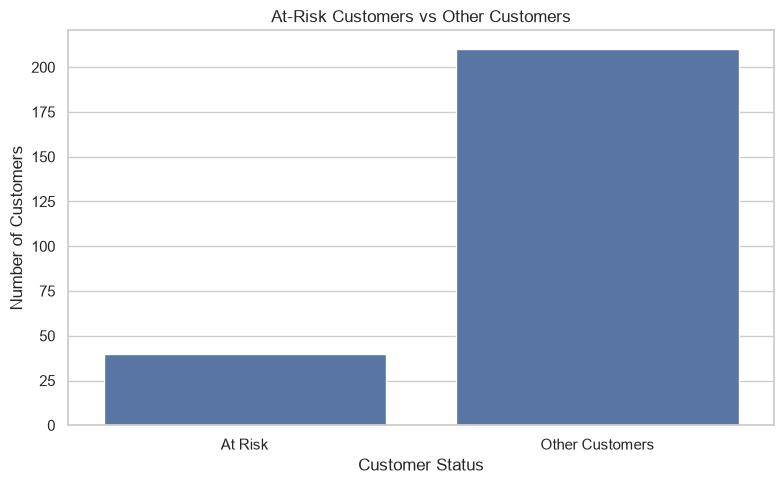

In [189]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Customer_Status"
)

plt.title("At-Risk Customers vs Other Customers")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("../images/05_at_risk_customers.png", dpi=300)
plt.show()

In [190]:
at_risk_summary = df[df["Satisfaction_Score"] < 50]

print("Total Customers:", len(df))
print("At-Risk Customers:", len(at_risk_summary))

print(
    "At-Risk Percentage:",
    round(len(at_risk_summary) / len(df) * 100, 2),
    "%"
)

print("\nAverage Complaints of At-Risk Customers:")
print(at_risk_summary["Complaints_Last_Year"].mean())

print("\nAverage Transactions of At-Risk Customers:")
print(at_risk_summary["Monthly_Transactions"].mean())

print("\nAverage Satisfaction of At-Risk Customers:")
print(at_risk_summary["Satisfaction_Score"].mean())

Total Customers: 250
At-Risk Customers: 40
At-Risk Percentage: 16.0 %

Average Complaints of At-Risk Customers:
1.075

Average Transactions of At-Risk Customers:
16.2

Average Satisfaction of At-Risk Customers:
43.290000000000006


In [191]:
df["Customer_Status"] = np.where(
    df["Satisfaction_Score"] < 50,
    "At Risk",
    "Other Customers"
)

comparison = df.groupby("Customer_Status")[
    [
        "Satisfaction_Score",
        "Complaints_Last_Year",
        "Monthly_Transactions",
        "Avg_Balance_INR",
        "Monthly_Income_INR"
    ]
].mean().round(2)

comparison

,Satisfaction_Score,Complaints_Last_Year,Monthly_Transactions,Avg_Balance_INR,Monthly_Income_INR
Customer_Status,,,,,
At Risk,43.29,1.08,16.20,66990.00,34487.18
Other Customers,65.58,0.99,23.65,170259.52,50298.54


In [192]:
import os

os.makedirs("../data/processed", exist_ok=True)

df.to_csv(
    "../data/processed/bank_data_clean.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [193]:
import os

file_path = "../data/processed/bank_data_clean.csv"

print("File exists:", os.path.exists(file_path))
print("File location:", file_path)

File exists: True
File location: ../data/processed/bank_data_clean.csv


In [194]:
df_clean = pd.read_csv(
    "../data/processed/bank_data_clean.csv"
)

print("Final shape:", df_clean.shape)

df_clean.head()

Final shape: (250, 16)


,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score,Balance_Income_Ratio,Age_Group,Satisfaction_Category,Customer_Status
0,C1149,mumbai,savings,salaried,mobile_app,31.0,14500.0,54600,12,1.0,2025-11-13,48.2,3.765517,26-35,Low,At Risk
1,C1123,delhi,savings,student,net_banking,40.0,56000.0,155500,16,1.0,2024-12-17,60.9,2.776786,36-50,Medium,Other Customers
2,C1215,delhi,savings,self_employed,mobile_app,55.0,66000.0,177400,14,1.0,2025-05-21,67.3,2.687879,51+,Medium,Other Customers
3,C1001,mumbai,salary,retired,mobile_app,26.0,78500.0,414700,33,1.0,2025-11-27,94.2,5.282803,26-35,High,Other Customers
4,C1009,jaipur,salary,self_employed,net_banking,44.0,62500.0,717200,12,1.0,2026-06-19,78.6,11.475200,36-50,High,Other Customers


In [195]:
print("=" * 40)
print("FINAL PROJECT DATA VERIFICATION")
print("=" * 40)

print("\nDataset Shape:")
print(df.shape)

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

print("\nFinal Verification Completed!")

FINAL PROJECT DATA VERIFICATION

Dataset Shape:
(250, 16)

Duplicate Rows:
0

Missing Values:
25

Column Names:
['Customer_ID', 'City', 'Account_Type', 'Employment_Type', 'Preferred_Channel', 'Age', 'Monthly_Income_INR', 'Avg_Balance_INR', 'Monthly_Transactions', 'Complaints_Last_Year', 'Last_Transaction_Date', 'Satisfaction_Score', 'Balance_Income_Ratio', 'Age_Group', 'Satisfaction_Category', 'Customer_Status']

Data Types:
Customer_ID                         str
City                                str
Account_Type                        str
Employment_Type                     str
Preferred_Channel                   str
Age                             float64
Monthly_Income_INR              float64
Avg_Balance_INR                   int64
Monthly_Transactions              int64
Complaints_Last_Year            float64
Last_Transaction_Date    datetime64[us]
Satisfaction_Score              float64
Balance_Income_Ratio            float64
Age_Group                      category
Satisfactio

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income_INR,Avg_Balance_INR,Monthly_Transactions,Complaints_Last_Year,Last_Transaction_Date,Satisfaction_Score,Balance_Income_Ratio,Age_Group,Satisfaction_Category,Customer_Status
0,C1149,mumbai,savings,salaried,mobile_app,31.0,14500.0,54600,12,1.0,2025-11-13,48.2,3.765517,26-35,Low,At Risk
1,C1123,delhi,savings,student,net_banking,40.0,56000.0,155500,16,1.0,2024-12-17,60.9,2.776786,36-50,Medium,Other Customers
2,C1215,delhi,savings,self_employed,mobile_app,55.0,66000.0,177400,14,1.0,2025-05-21,67.3,2.687879,51+,Medium,Other Customers
3,C1001,mumbai,salary,retired,mobile_app,26.0,78500.0,414700,33,1.0,2025-11-27,94.2,5.282803,26-35,High,Other Customers
4,C1009,jaipur,salary,self_employed,net_banking,44.0,62500.0,717200,12,1.0,2026-06-19,78.6,11.475200,36-50,High,Other Customers



Final Verification Completed!


In [196]:
import os

image_folder = "../images"

if os.path.exists(image_folder):
    print("Images folder exists.")

    for file in os.listdir(image_folder):
        print(file)
else:
    print("Images folder is missing.")

Images folder exists.
01_overall_satisfaction.png
02_balance_transactions.png
03_correlation.png
04_group_comparison.png
05_at_risk_customers.png
